# 完整流程示例（对照 CLI 页）

路径用 `meteva_base.get_path`；数据根目录为 `resource/data/common_domain/`（视为业务输入）。

**单位说明**

- 本示例 EC TMP_2M 的 `units` 为 **℃**。
- `LapseRate` / `ApplyGriddedLapseRate` 对 `DataArray` 会读 `attrs['units']`，经 `convert_units` **转到 K（及 K/m、m）再计算**。
- Apply 写出的订正气温 **`units='K'`**。
- 下面四张平面图一律画成 **℃**（订正/实况：K−273.15；EC：已是 ℃ 则直接画）。
- EC / 订正 / 实况 **共用同一套色标**；Γ 单独色标。

**时次**：EC 为世界时 `00Z+.000`；实况 HRCLDAS 文件名为**北京时**，取 `有效世界时 + 8h` 的整点（即 `…TAIR-YYYYMMDD0800`）。


## 1. 准备

In [1]:
from __future__ import annotations

import sys
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import meteva_base as meb
import xarray as xr

# 包根 = nbs 的上一级；00temp 用于 import
PKG = Path("..").resolve()
sys.path[:0] = [str(PKG.parent), str(PKG)]

from orographic_temperature_downscaling.cli.dsc_temp_lapse_rate import process as est_gamma
from orographic_temperature_downscaling.cli.anc_lapse_rate import process as apply_gamma

DATA = PKG / "resource" / "data" / "common_domain"
OBS_ROOT = PKG / "resource" / "data" / "hrcldas_tair"

# get_path 模板
EC_TPL = str(DATA / "ec_tmp2m" / "YYYY" / "YYYYMMDD" / "YYYYMMDDHH.TTT.nc")
LAPSE_TPL = str(DATA / "output" / "lapse" / "YYYYMMDDHH.TTT.nc")
CORR_TPL = str(DATA / "output" / "corr" / "YYYYMMDDHH.TTT.nc")

OROG = str(DATA / "ancil" / "ec_source_orography.nc")       # 源地形（静态）
MASK = str(DATA / "ancil" / "ec_land_sea_mask.nc")          # 海陆掩码（静态）
DEST_OROG = str(DATA / "ancil" / "HGT_M_1KM_CHINA.nc")      # 目标 1 km 地形
FIG = DATA / "output" / "figs"
FIG.mkdir(parents=True, exist_ok=True)
(DATA / "output" / "lapse").mkdir(parents=True, exist_ok=True)
(DATA / "output" / "corr").mkdir(parents=True, exist_ok=True)

# 15 个 00 起报，时效 000（与北京时 08 实况对齐）
START, N_DAYS, DTIME = datetime(2026, 10, 10, 0), 15, 0
cycles = [START + timedelta(days=i) for i in range(N_DAYS)]
print("example EC:", meb.get_path(EC_TPL, cycles[0], DTIME))


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


example EC: D:\workspace\test\00temp\orographic_temperature_downscaling\resource\data\common_domain\ec_tmp2m\2026\20261010\2026101000.000.nc


## 2. 批量估 Γ → 插到 1 km → Apply

已有输出时可把 `RUN_LAPSE` / `RUN_APPLY` 设为 `False`。

In [2]:
RUN_LAPSE = False   # 首次或需重算改为 True
RUN_APPLY = False

# ---- 2.1 粗网格估 Γ ----
for t0 in cycles:
    ec = meb.get_path(EC_TPL, t0, DTIME)
    out = meb.get_path(LAPSE_TPL, t0, DTIME)
    if RUN_LAPSE or not Path(out).exists():
        est_gamma(ec, orography_path=OROG, land_sea_mask_path=MASK, output_path=out)
print("lapse done")

# ---- 2.2 源地形插到 1 km（只做一次）----
dest = meb.read_griddata_from_nc(DEST_OROG)
dest.attrs["units"] = "m"
grid1km = meb.get_grid_of_data(dest)
src0 = meb.read_griddata_from_nc(OROG)
src0.attrs["units"] = "m"
src1km = meb.interp_gg_linear(src0, grid1km, outer_value=np.nan)
src1km.attrs["units"] = "m"

# ---- 2.3 逐日：气温/Γ → 1 km → Apply（订正结果为 K）----
tmp = DATA / "output" / "corr" / "_tmp"
tmp.mkdir(exist_ok=True)
for t0 in cycles:
    tag = t0.strftime("%Y%m%d%H") + f".{DTIME:03d}"
    corr_out = meb.get_path(CORR_TPL, t0, DTIME)
    if not RUN_APPLY and Path(corr_out).exists():
        continue
    # 读入；Apply/LapseRate 会对 DataArray 按 units 转到 K
    t = meb.read_griddata_from_nc(meb.get_path(EC_TPL, t0, DTIME))
    g = meb.read_griddata_from_nc(meb.get_path(LAPSE_TPL, t0, DTIME))
    g.attrs["units"] = "K m-1"
    # 显式转到 K，避免 ℃ 字符串不被 cf_units 识别
    if str(t.attrs.get("units", "")) in ("℃", "C", "degC", "celsius", "Celsius"):
        t = t.copy(data=np.asarray(t.values, dtype=np.float32) + 273.15)
        t.attrs["units"] = "K"
    t1 = meb.interp_gg_linear(t, grid1km, outer_value=np.nan)
    g1 = meb.interp_gg_linear(g, grid1km, outer_value=np.nan)
    t1.attrs["units"] = "K"
    g1.attrs["units"] = "K m-1"
    # 静态场时间维与气温对齐
    kw = dict(time=t1.time.values, dtime=t1.dtime.values, member=t1.member.values, level=t1.level.values)
    s1 = src1km.assign_coords(**kw)
    d1 = dest.assign_coords(**kw)
    for name, grd in ("t.nc", t1), ("g.nc", g1), ("s.nc", s1), ("d.nc", d1):
        meb.write_griddata_to_nc(grd, str(tmp / name), creat_dir=True)
    apply_gamma(str(tmp / "t.nc"), str(tmp / "g.nc"), str(tmp / "s.nc"), str(tmp / "d.nc"), output_path=corr_out)
    print("corr", tag)
print("apply done")


lapse done
apply done


## 3. 四张图（抽第 1 天）

1 输入 EC（℃）　2 Γ（K/m）　3 订正（℃）　4 实况（℃）  
其中 1 / 3 / 4 **同一色标**。

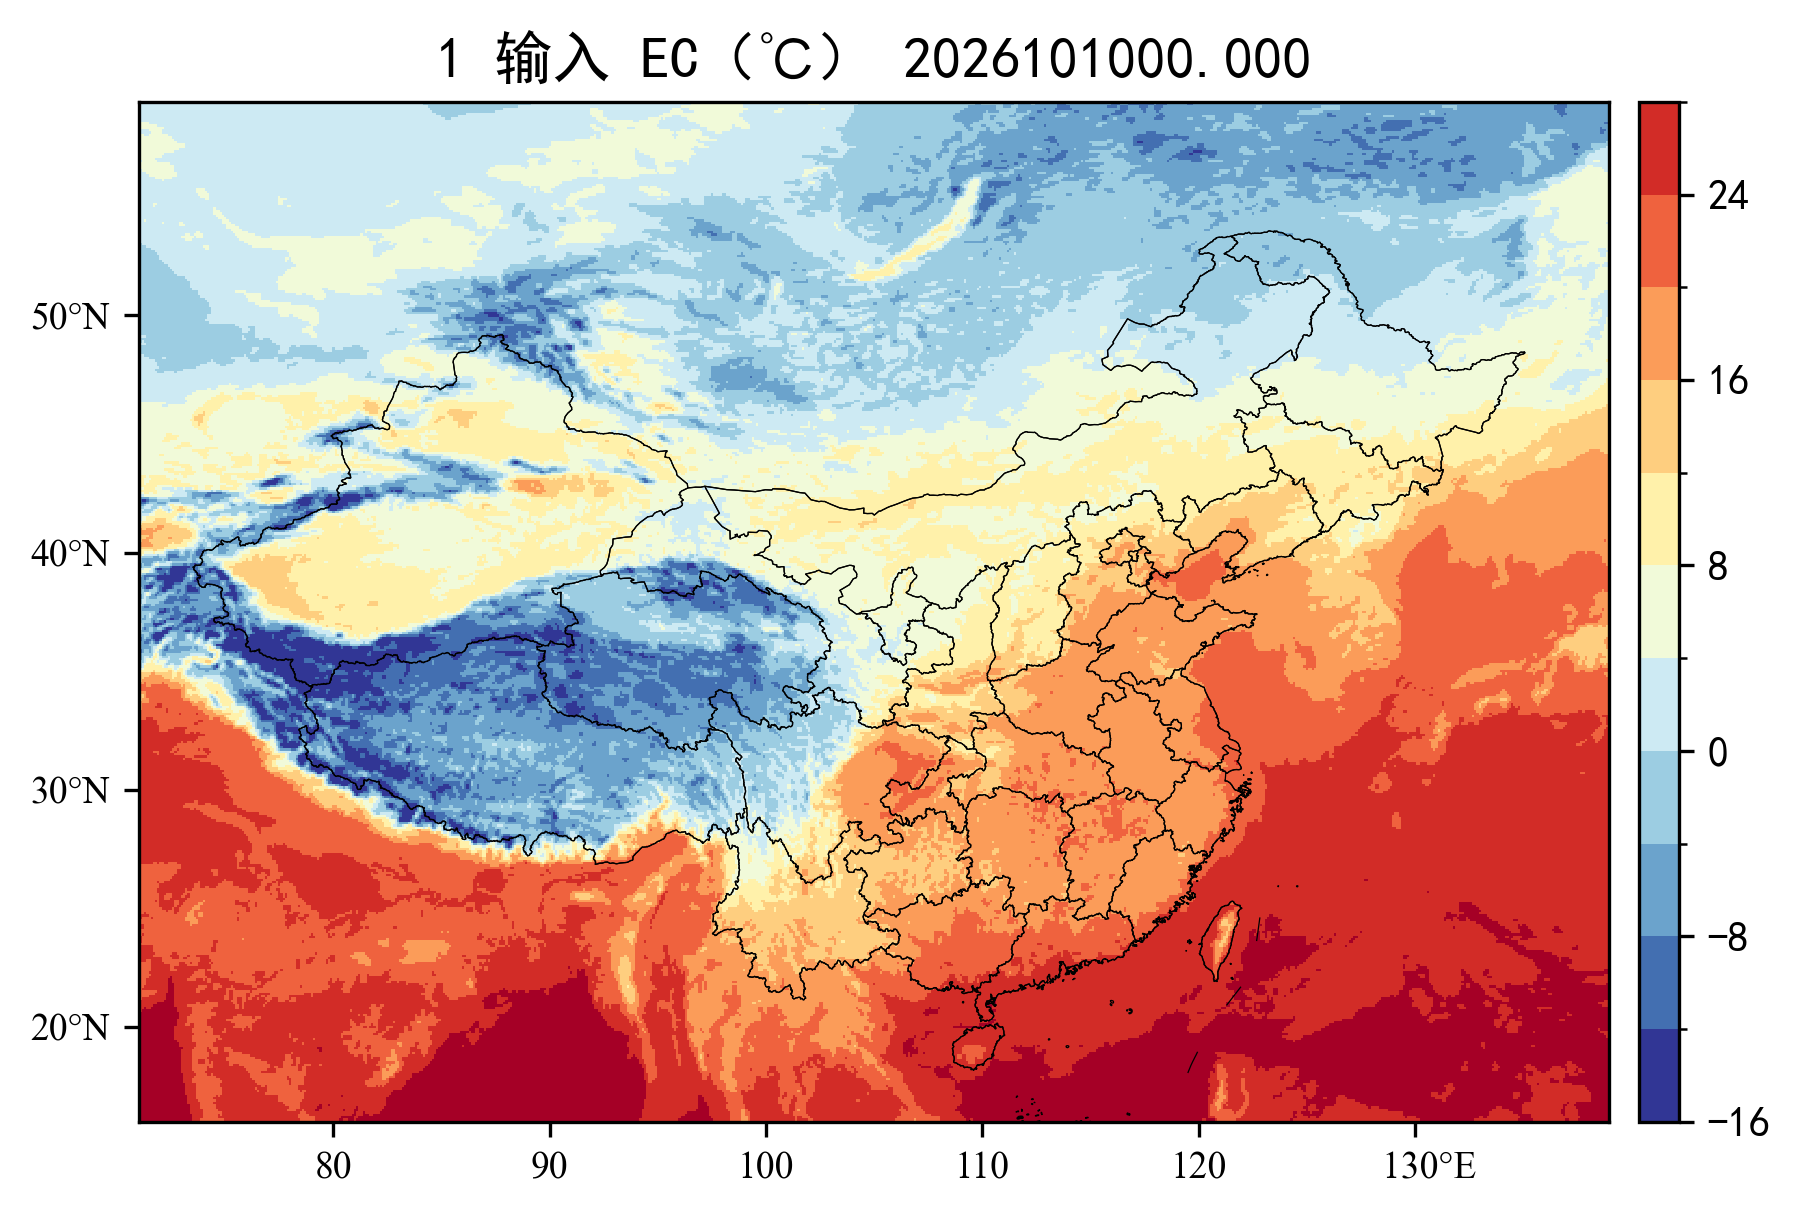

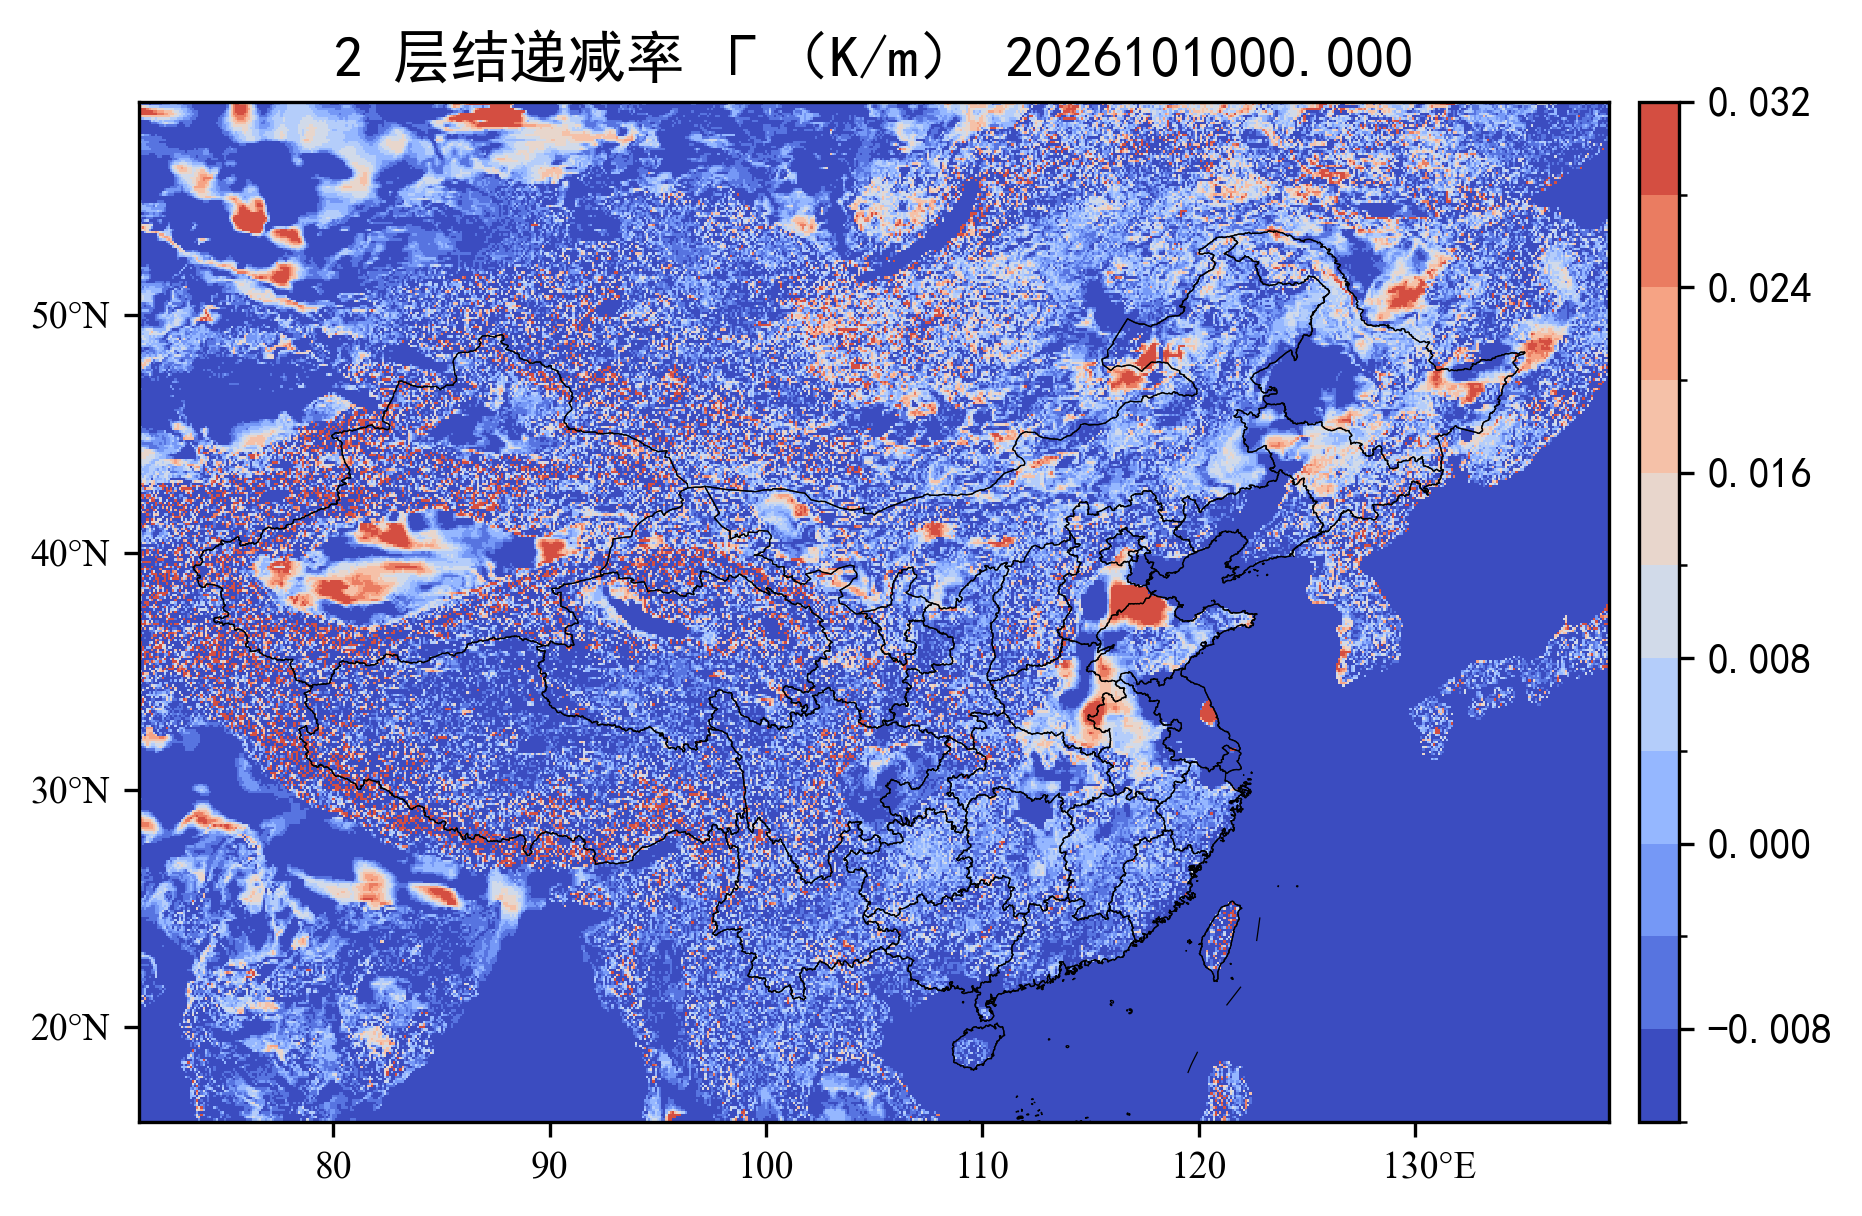

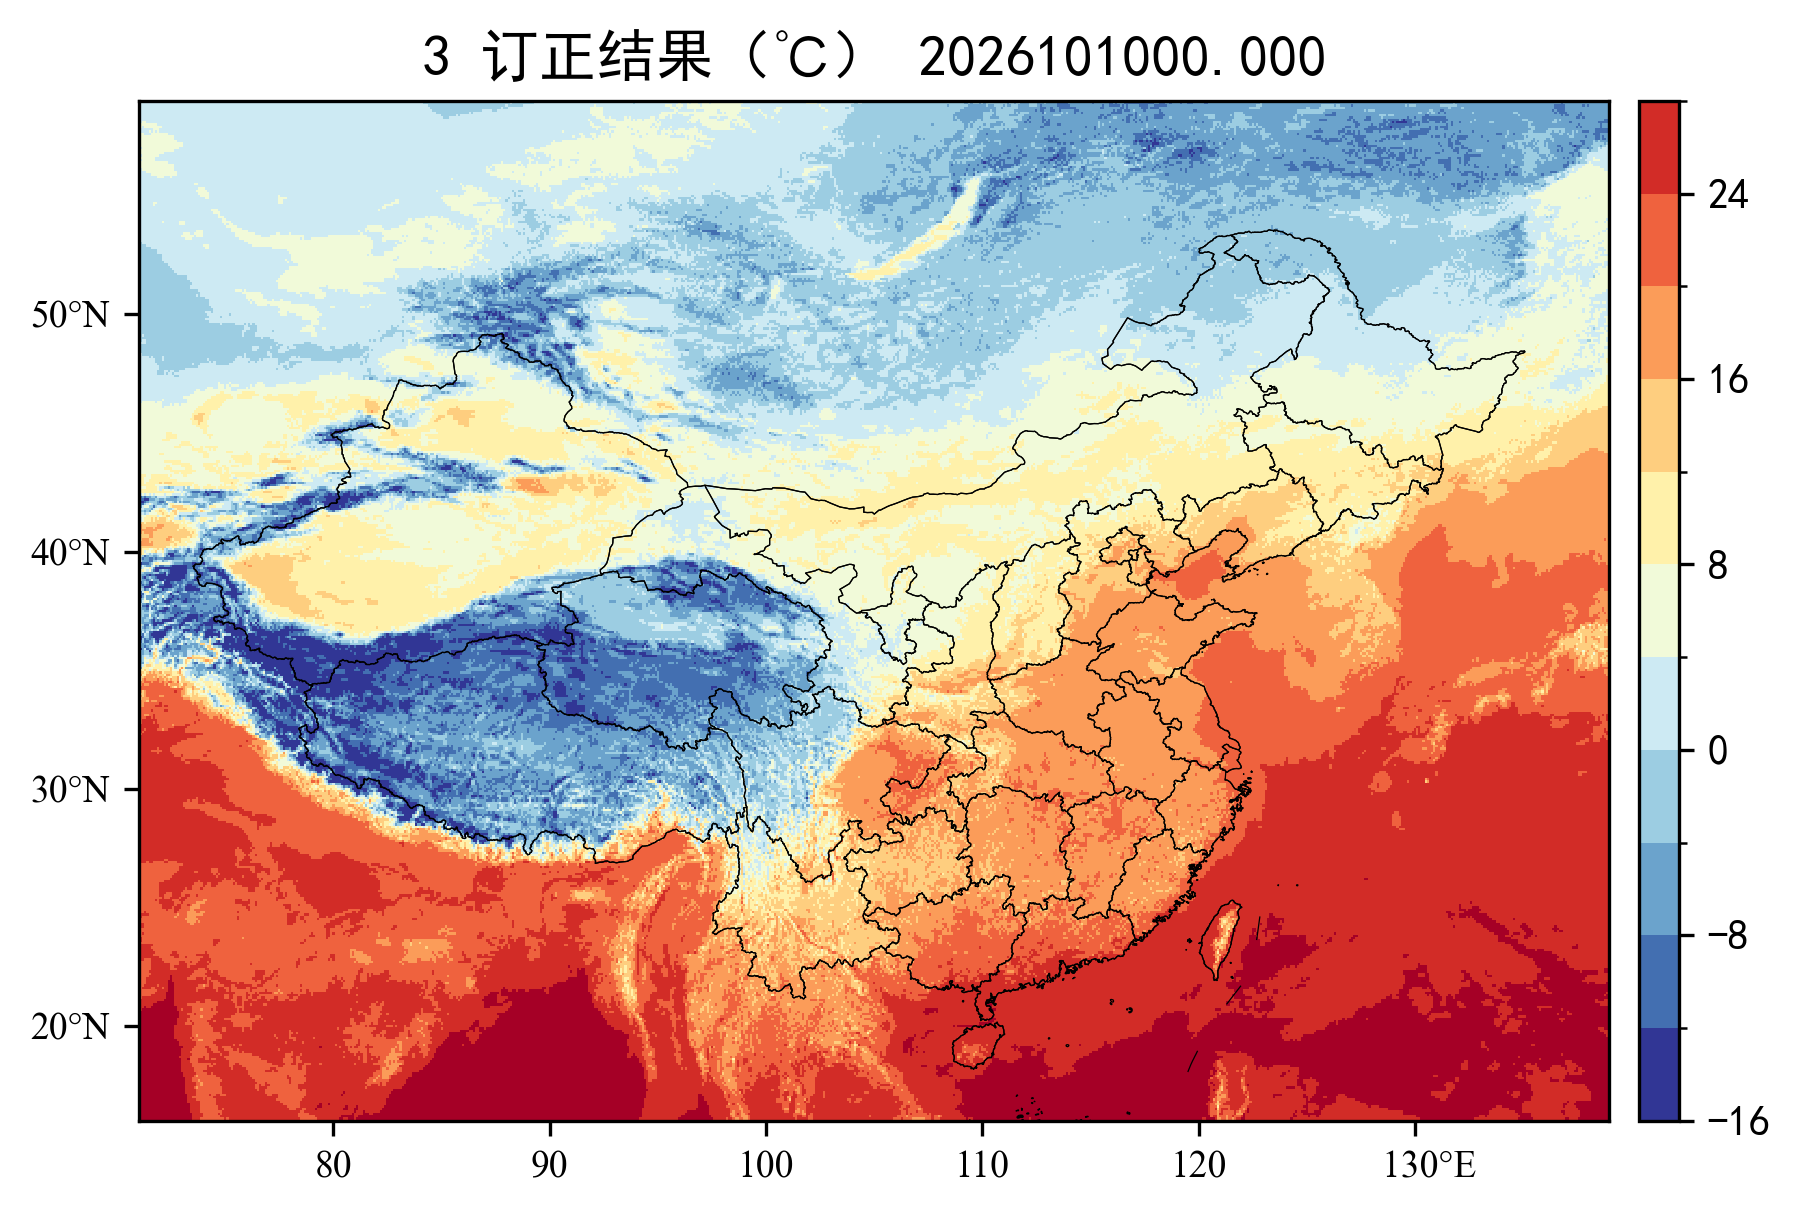

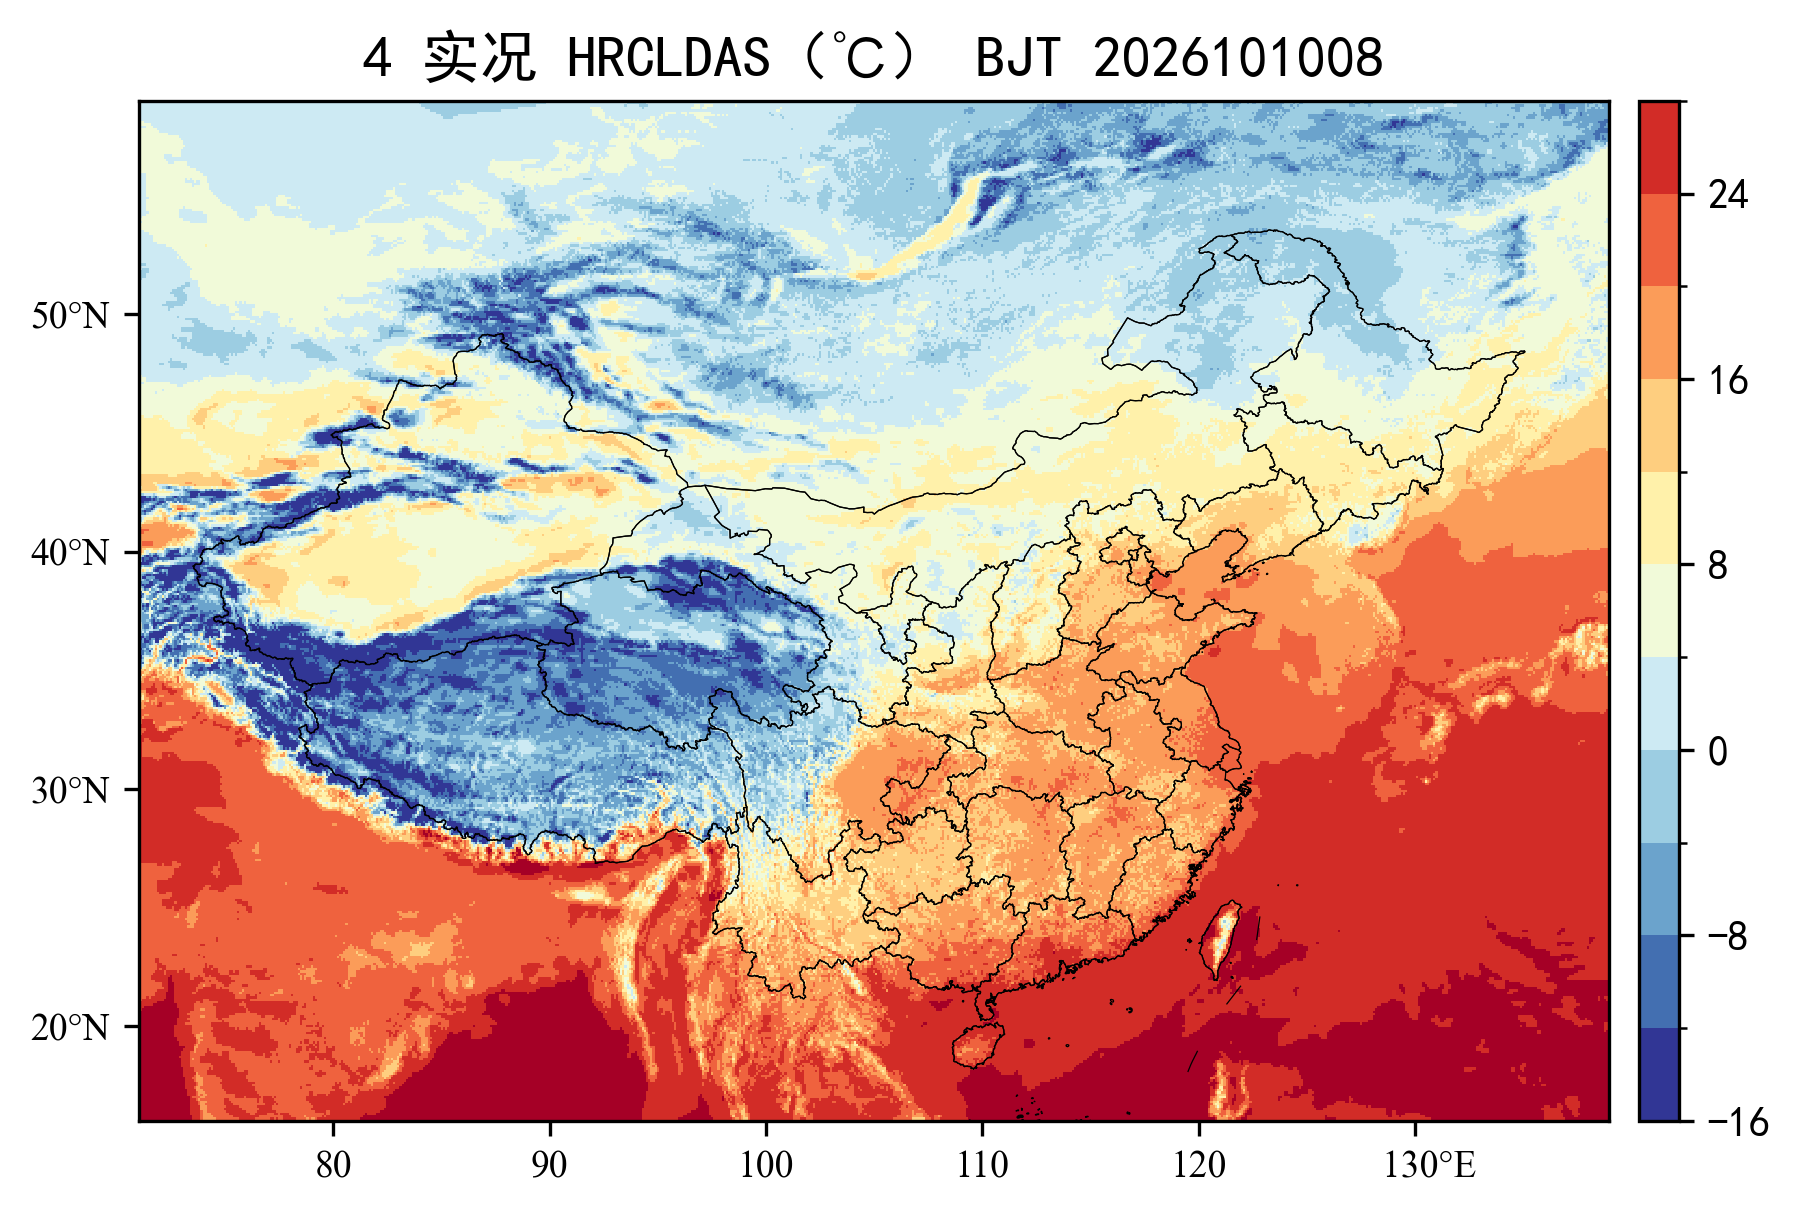

figs: D:\workspace\test\00temp\orographic_temperature_downscaling\resource\data\common_domain\output\figs


In [3]:
t0 = cycles[0]
tag = t0.strftime("%Y%m%d%H") + f".{DTIME:03d}"
valid = t0 + timedelta(hours=DTIME)
step = 10  # 细网格绘图抽稀
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

# --- 读场并统一到 ℃（meb 格点，供 pcolormesh_2d_grid）---
ec = meb.read_griddata_from_nc(meb.get_path(EC_TPL, t0, DTIME))
ec_c = ec.copy(data=np.asarray(ec.values, dtype=np.float32))  # 已是 ℃
ec_c.name, ec_c.attrs["units"] = "t2m", "degC"

gamma = meb.read_griddata_from_nc(meb.get_path(LAPSE_TPL, t0, DTIME))

corr = meb.read_griddata_from_nc(meb.get_path(CORR_TPL, t0, DTIME))  # K
corr = corr.isel(lat=slice(None, None, step), lon=slice(None, None, step))
corr_c = corr.copy(data=np.asarray(corr.values, dtype=np.float32) - 273.15)
corr_c.name, corr_c.attrs["units"] = "t2m", "degC"

# 实况：EC 世界时 → 北京时 +8h
bjt = valid + timedelta(hours=8)
day, hhmm = bjt.strftime("%Y%m%d"), bjt.strftime("%H%M")
obs_p = next((OBS_ROOT / bjt.strftime("%Y") / day).glob(f"*TAIR-{day}{hhmm}.GRB2"))
da = xr.open_dataset(str(obs_p), engine="cfgrib")["t2m"]
dest = meb.read_griddata_from_nc(DEST_OROG)
da = da.sel(
    latitude=slice(float(dest.lat.min()), float(dest.lat.max())),
    longitude=slice(float(dest.lon.min()), float(dest.lon.max())),
).reindex(latitude=dest.lat.values, longitude=dest.lon.values, method="nearest", tolerance=0.006)
obs = meb.grid_data(meb.get_grid_of_data(dest), data=np.asarray(da.values, dtype=np.float32))
obs = obs.isel(lat=slice(None, None, step), lon=slice(None, None, step))
obs_c = obs.copy(data=np.asarray(obs.values, dtype=np.float32) - 273.15)
obs_c.name, obs_c.attrs["units"] = "t2m", "degC"

# EC / 订正 / 实况 共用 clevs（pcolormesh_2d_grid 自带省界）
both = np.concatenate([
    np.asarray(ec_c.values).ravel(),
    np.asarray(corr_c.values).ravel(),
    np.asarray(obs_c.values).ravel(),
])
both = both[np.isfinite(both)]
tmin = np.floor(np.nanpercentile(both, 1) / 2) * 2
tmax = np.ceil(np.nanpercentile(both, 99) / 2) * 2
# meb 在色标级数≥20 时会按单场 vmin/vmax 裁切色标，须保持 <20 才能三图一致
step = 2.0
t_clevs = np.arange(tmin, tmax + 0.1, step)
while len(t_clevs) >= 20:
    step *= 2
    t_clevs = np.arange(tmin, tmax + 0.1, step)
t_clevs = t_clevs.tolist()

pcolormesh_2d_grid(
    ec_c, save_path=str(FIG / f"{tag}_1_ec_C.png"), title=f"1 输入 EC（℃） {tag}",
    clevs=t_clevs, cmap="RdYlBu_r", show=True,
)
pcolormesh_2d_grid(
    gamma, save_path=str(FIG / f"{tag}_2_lapse.png"), title=f"2 层结递减率 Γ（K/m） {tag}",
    cmap="coolwarm", show=True,
)
pcolormesh_2d_grid(
    corr_c, save_path=str(FIG / f"{tag}_3_corr_C.png"), title=f"3 订正结果（℃） {tag}",
    clevs=t_clevs, cmap="RdYlBu_r", show=True,
)
pcolormesh_2d_grid(
    obs_c, save_path=str(FIG / f"{tag}_4_obs_C.png"),
    title=f"4 实况 HRCLDAS（℃） BJT {bjt:%Y%m%d%H}",
    clevs=t_clevs, cmap="RdYlBu_r", show=True,
)
print("figs:", FIG)


## 4. 验证 Bias / RMSE（订正前 / 订正后 vs 实况）

- **订正前**：EC 插到 1 km（℃→K）vs 实况 K。
- **订正后**：Apply 结果 K vs 实况 K。
- 同一掩码（有限值交集），并输出 ΔRMSE = 订正后 − 订正前（负值表示改善）。

In [4]:
def _bias_rmse(pred: np.ndarray, obs: np.ndarray) -> tuple[float, float]:
    m = np.isfinite(pred) & np.isfinite(obs)
    d = pred[m] - obs[m]
    return float(np.mean(d)), float(np.sqrt(np.mean(d**2)))


rows = []
dest = meb.read_griddata_from_nc(DEST_OROG)
grid1km = meb.get_grid_of_data(dest)
for t0 in cycles:
    tag = t0.strftime("%Y%m%d%H") + f".{DTIME:03d}"
    valid = t0 + timedelta(hours=DTIME)

    # 订正前：EC → K → 插到 1 km（与 Apply 输入对齐）
    t = meb.read_griddata_from_nc(meb.get_path(EC_TPL, t0, DTIME))
    if str(t.attrs.get("units", "")) in ("℃", "C", "degC", "celsius", "Celsius"):
        t = t.copy(data=np.asarray(t.values, dtype=np.float32) + 273.15)
        t.attrs["units"] = "K"
    before = meb.interp_gg_linear(t, grid1km, outer_value=np.nan)

    # 订正后：Apply 输出（K）
    corr = meb.read_griddata_from_nc(meb.get_path(CORR_TPL, t0, DTIME))

    # 实况：EC 世界时 → 北京时（+8h），对齐到 1 km
    bjt = valid + timedelta(hours=8)
    day, hhmm = bjt.strftime("%Y%m%d"), bjt.strftime("%H%M")
    obs_p = next((OBS_ROOT / bjt.strftime("%Y") / day).glob(f"*TAIR-{day}{hhmm}.GRB2"))
    da = xr.open_dataset(str(obs_p), engine="cfgrib")["t2m"]
    da = da.sel(
        latitude=slice(float(dest.lat.min()), float(dest.lat.max())),
        longitude=slice(float(dest.lon.min()), float(dest.lon.max())),
    ).reindex(latitude=dest.lat.values, longitude=dest.lon.values, method="nearest", tolerance=0.006)

    b = np.asarray(da.values, dtype=float).ravel()
    a0 = np.asarray(before.values, dtype=float).ravel()
    a1 = np.asarray(corr.values, dtype=float).ravel()
    bias0, rmse0 = _bias_rmse(a0, b)
    bias1, rmse1 = _bias_rmse(a1, b)
    rows.append((tag, bias0, rmse0, bias1, rmse1))
    print(
        f"{tag}  before bias={bias0:.3f}K rmse={rmse0:.3f}K | "
        f"after bias={bias1:.3f}K rmse={rmse1:.3f}K | "
        f"Δrmse={rmse1 - rmse0:+.3f}K"
    )

mean_b0 = float(np.mean([r[1] for r in rows]))
mean_r0 = float(np.mean([r[2] for r in rows]))
mean_b1 = float(np.mean([r[3] for r in rows]))
mean_r1 = float(np.mean([r[4] for r in rows]))
print(
    f"mean  before bias={mean_b0:.3f}K rmse={mean_r0:.3f}K | "
    f"after bias={mean_b1:.3f}K rmse={mean_r1:.3f}K | "
    f"Δrmse={mean_r1 - mean_r0:+.3f}K"
)


2026101000.000  before bias=0.034K rmse=2.199K | after bias=-0.065K rmse=1.910K | Δrmse=-0.289K
2026101100.000  before bias=0.140K rmse=2.216K | after bias=0.039K rmse=1.918K | Δrmse=-0.298K
2026101200.000  before bias=0.070K rmse=2.165K | after bias=-0.035K rmse=1.866K | Δrmse=-0.299K
2026101300.000  before bias=0.089K rmse=2.074K | after bias=-0.013K rmse=1.756K | Δrmse=-0.318K
2026101400.000  before bias=0.138K rmse=2.160K | after bias=0.037K rmse=1.845K | Δrmse=-0.315K
2026101500.000  before bias=0.124K rmse=2.099K | after bias=0.022K rmse=1.787K | Δrmse=-0.311K
2026101600.000  before bias=0.363K rmse=1.994K | after bias=0.259K rmse=1.654K | Δrmse=-0.340K
2026101700.000  before bias=0.339K rmse=2.053K | after bias=0.234K rmse=1.715K | Δrmse=-0.338K
2026101800.000  before bias=0.089K rmse=2.050K | after bias=-0.013K rmse=1.727K | Δrmse=-0.324K
2026101900.000  before bias=0.168K rmse=2.069K | after bias=0.064K rmse=1.745K | Δrmse=-0.323K
2026102000.000  before bias=0.110K rmse=2.107K